In [1]:
import tiktoken
import torch
import torch.nn as nn

In [2]:

class GELU(nn.Module):
    def __init__(self):
        super().__init__()

    def forward(self, x):
        return 0.5 * x * (1 + torch.tanh(
            torch.sqrt(torch.tensor(2.0 / torch.pi, device=x.device)) *
            (x + 0.044715 * torch.pow(x, 3))
        ))
    

class LayerNorm(nn.Module):
    def __init__(self, emb_dim):
        super().__init__()
        self.eps = 1e-5
        self.scale = nn.Parameter(torch.ones(emb_dim))
        self.shift = nn.Parameter(torch.zeros(emb_dim))

    def forward(self, x):
        mean = x.mean(dim=-1, keepdim=True)
        var = x.var(dim=-1, keepdim=True, unbiased=False)
        norm_x = (x - mean)/ torch.sqrt(var + self.eps)
        return self.scale * norm_x + self.shift
    

class FeedForward(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Linear(cfg["emb_dim"], 4 * cfg["emb_dim"]),
            GELU(),
            nn.Linear(4 * cfg["emb_dim"], cfg["emb_dim"])
        )

    def forward(self, x):
        return self.layers(x)


class MultiHeadAttention(nn.Module):
    def __init__(self, d_in, d_out, context_length, num_heads, dropout, qkv_bias=False, max_seq_len=None, window_size=None):
        super().__init__()
        assert d_out % num_heads == 0, "d_out must be divisible by num_heads"

        self.d_in = d_in
        self.d_out = d_out
        self.num_heads = num_heads
        self.head_dim = self.d_out // num_heads

        self.W_query = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_key = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_value = nn.Linear(d_in, d_out, bias=qkv_bias)

        self.out_proj = nn.Linear(d_out, d_out)
        self.dropout = nn.Dropout(dropout)

        self.max_seq_len = max_seq_len or context_length
        self.window_size = window_size or self.max_seq_len
        # self.register_buffer('mask', torch.triu(torch.ones(context_length, context_length), diagonal=1))
        self.register_buffer('cache_k', None, persistent=False) # persistent - whether the buffer is part of the module’s state_dict
        self.register_buffer('cache_v', None, persistent=False)  # persistent - whether the buffer is part of the module’s state_dict

    def forward(self, x, use_cache=False):
        batch, num_tokens, dim = x.shape

        if use_cache:
            assert num_tokens <= self.window_size, (
                f"Input chunk size ({num_tokens}) exceeds KV cache window size ({self.window_size}). "
            )

        queries = self.W_query(x)
        values_new = self.W_value(x)
        keys_new = self.W_key(x)

        queries = queries.view(batch, num_tokens, self.num_heads, self.head_dim)
        values_new = values_new.view(batch, num_tokens, self.num_heads, self.head_dim)
        keys_new = keys_new.view(batch, num_tokens, self.num_heads, self.head_dim)

        queries = queries.transpose(1,2)
        values_new = values_new.transpose(1,2)
        keys_new = keys_new.transpose(1,2)

        if use_cache:

            if self.cache_k is None or self.cache_k.size(0) != batch:
                self.cache_k = torch.zeros(batch, self.num_heads, self.window_size, self.head_dim, device=x.device)
                self.cache_v = torch.zeros_like(self.cache_k)
                self.ptr_cur = 0

            # Discard oldest tokens, if overflow
            if self.ptr_cur + num_tokens > self.window_size:
                overflow = self.ptr_cur + num_tokens  - self.window_size
                self.cache_k[:, :, :-overflow, :] = self.cache_k[:, :, overflow:, :].clone() # Shift cache left by `overflow` tokens.
                self.cache_v[:, :, :-overflow, :] = self.cache_v[:, :, overflow:, :].clone() # Example: if overflow = 5, tokens [5:] are moved to the front and the first 5 (oldest) tokens are discarded.
                self.ptr_cur -= overflow
                
                # overflow = 3
                # index:   0 1 2 3 4 5 6 7 8 9
                # values: [A B C D E F G H I J]
                # [:-3]: [A B C D E F G]
                # [:3]:   [D E F G H I J]   
                # [A B C D E F G] = [D E F G H I J]   
                # result: [D E F G H I J ? ? ?]   ? tokens are waiting to e overwritten
            self.cache_k[:, :, self.ptr_cur:self.ptr_cur + num_tokens, :] = keys_new
            self.cache_v[:, :, self.ptr_cur:self.ptr_cur + num_tokens, :] = values_new
            self.ptr_cur += num_tokens

            keys = self.cache_k[:, :, :self.ptr_cur, :]
            values = self.cache_v[:, :, :self.ptr_cur, :]

        else:
            keys, values = keys_new, values_new
            self.ptr_cur = 0

        attn_scores = queries @ keys.transpose(2, 3) # (batch, heads, Q, K)


        K = attn_scores.size(-1) # number of Keys
        if num_tokens == K:
            # No cache → use the pre‑baked triangular mask slice
            causal_mask = torch.triu(torch.ones(num_tokens, K, device=x.device, dtype=torch.bool), diagonal=1)
        else:
            # cached
            offset = K - num_tokens # number of tokens already in cache before this chunk
            row_idx = torch.arange(num_tokens, device=x.device).unsqueeze(1) # (num_tokens, 1) -> query token positions. row 0 → first new token, row 1 → second new token
            col_idx = torch.arange(K, device=x.device).unsqueeze(0) # (1, K) # key positions, col 0 → first cached token, col 5 → newest token
            # unsqeezes -> for broadcasting (num_tokens, K)
            causal_mask = row_idx + offset < col_idx # True where j > i+offset: mask future tokens; Query index i can see keys up to (offset + i)
            # offset to catch the correct index: cache have older indicies, query newer -> missmatch.

            # Example: num_tokens=2, K=8, offset=6
            #
            #   row_idx          [[0], [1]]          (num_tokens, 1)
            #   col_idx          [[0 1 2 3 4 5 6 7]] (1, K)
            #   row_idx + offset [[6], [7]]
            #
            #   row_idx + offset < col_idx:
            #     6 < [0..7] → F F F F F F F T
            #     7 < [0..7] → F F F F F F F F
            #
            #   Q0 (pos 6) attends to keys ≤6, Q1 (pos 7) attends to keys ≤7

        attn_scores.masked_fill_(causal_mask.unsqueeze(0).unsqueeze(0), -torch.inf)
        
        attn_weights = torch.softmax(attn_scores / keys.shape[-1]**0.5, dim=-1)
        attn_weights = self.dropout(attn_weights)

        context_vector = (attn_weights @ values).transpose(1,2)
        context_vector = context_vector.contiguous().view(batch, num_tokens, self.d_out)
        context_vector = self.out_proj(context_vector)

        return context_vector

    def reset_cache(self):
        self.cache_k, self.cache_v = None, None
        self.ptr_cur = 0


class TransformerBlock(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.att = MultiHeadAttention(
            d_in=cfg["emb_dim"],
            d_out=cfg["emb_dim"],
            context_length=cfg["context_length"],
            num_heads=cfg["n_heads"],
            dropout=cfg["drop_rate"],
            qkv_bias=cfg["qkv_bias"]
        )
        self.ff = FeedForward(cfg)
        self.norm1 = LayerNorm(cfg["emb_dim"])
        self.norm2 = LayerNorm(cfg["emb_dim"])
        self.drop_shortcut = nn.Dropout(cfg["drop_rate"])

    def forward(self, x, use_cache=False):
        # Shortcut connection for attention block
        shortcut = x
        x = self.norm1(x)
        x = self.att(x,use_cache=use_cache)
        x = self.drop_shortcut(x)
        x = x + shortcut

        # Shortcut connection for feed forward block
        shortcut = x
        x = self.norm2(x)
        x = self.ff(x)
        x = self.drop_shortcut(x)
        x = x + shortcut

        return x


class GPTModel(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.tok_emb = nn.Embedding(cfg["vocab_size"], cfg["emb_dim"])
        self.pos_emb = nn.Embedding(cfg["context_length"], cfg["emb_dim"])
        self.drop_emb = nn.Dropout(cfg["drop_rate"])

        self.trf_blocks = nn.ModuleList(
            [TransformerBlock(cfg) for _ in range(cfg["n_layers"])])
        self.ptr_current_pos = 0

        self.final_norm = LayerNorm(cfg["emb_dim"])
        self.head_out = nn.Linear(cfg["emb_dim"], cfg["vocab_size"], bias=False)
        self.kv_window_size = cfg["kv_window_size"]  if "kv_window_size" in cfg else cfg["context_length"]

    def forward(self, in_idx, use_cache=False):
        batch_size, seq_len = in_idx.shape
        tok_embeds = self.tok_emb(in_idx)
        if use_cache:
            context_length = self.pos_emb.num_embeddings
            assert self.ptr_current_pos + seq_len <= context_length, (
                f"Position embedding overflow. Want to read {self.ptr_current_pos + seq_len} which excceded size of {context_length}"
            )
            pos_ids = torch.arange(self.ptr_current_pos, self.ptr_current_pos + seq_len, device=in_idx.device, dtype=torch.long)
            self.ptr_current_pos += seq_len
        else:
            pos_ids = torch.arange(seq_len, device = in_idx.device, dtype=torch.long)

        pos_embeds = self.pos_emb(pos_ids)

        x = tok_embeds + pos_embeds
        x = self.drop_emb(x)
        for blk in self.trf_blocks:
            x = blk(x, use_cache=use_cache)
        x = self.final_norm(x)
        logits = self.head_out(x)

        return logits 

    def reset_kv_cache(self):
        for blk in self.trf_blocks:
            blk.att.reset_cache()
        self.ptr_current_pos = 0       
    

In [3]:
GPT_CONFIG_124M = {
    "vocab_size": 50257,   # Vocabulary size
    "context_length": 256, # Shortened context length (orig: 1024)
    "emb_dim": 768,        # Embedding dimension
    "n_heads": 12,         # Number of attention heads
    "n_layers": 12,        # Number of layers
    "drop_rate": 0.1,      # Dropout rate
    "qkv_bias": False      # Query-key-value bias
}

torch.manual_seed(123)
model = GPTModel(GPT_CONFIG_124M)
model.eval();  # Disable dropout during inference

In [4]:
def generate_text_simple_cached(model, idx, max_new_tokens, context_size=None, use_cache=True):
    model.eval()
    ctx_len = context_size or model.pos_emb.num_embeddings
    kv_window_size = model.kv_window_size
    
    with torch.no_grad():
        if use_cache:
            # Init cache with full prompt
            input_tokens = idx[:, -ctx_len:]
            input_tokens_length = input_tokens.size(1)

            # prefill to handle input_tokens_length > kv_window_size
            # It's needed when: prompt length > KV window size
            for i in range(0, input_tokens_length, kv_window_size):
                chunk = input_tokens[:, i:i + kv_window_size]
                logits = model(chunk, use_cache=True)

            # can't generate more than ctx_len of result
            # due to the limitation of position embedding
            max_generable = ctx_len - input_tokens_length
            max_new_tokens = min(max_generable, max_new_tokens)

            for _ in range(max_new_tokens):
                next_idx = logits[:,-1].argmax(dim=-1, keepdim=True)
                idx = torch.cat([idx, next_idx], dim=1)
                logits = model(next_idx, use_cache = True)

        else:
            for _ in range(max_new_tokens):
                logits = model(idx[:, -ctx_len:], use_cache=use_cache)
                next_idx = logits[:, -1].argmax(dim=-1, keepdim=True)
                idx = torch.cat([idx, next_idx], dim=1)

        return idx

In [5]:
def text_to_token_ids(text, tokenizer):
    encoded = tokenizer.encode(text, allowed_special={'<|endoftext|>'})
    encoded_tensor = torch.tensor(encoded).unsqueeze(0) # add batch dimension
    return encoded_tensor

def token_ids_to_text(token_ids, tokenizer):
    flat = token_ids.squeeze(0) # remove batch dimension
    return tokenizer.decode(flat.tolist())

start_context = "Every effort moves you"
tokenizer = tiktoken.get_encoding("gpt2")


token_ids = generate_text_simple_cached(
    model=model,
    idx=text_to_token_ids(start_context, tokenizer),
    max_new_tokens=10,
    context_size=GPT_CONFIG_124M["context_length"],
    use_cache=True
)

print("Output text:\n", token_ids_to_text(token_ids, tokenizer))

Output text:
 Every effort moves you rentingetic wasnم refres RexMeCHicular stren


In [6]:
inputs = torch.tensor([[16833, 3626, 6100],   # ["every effort moves",
                       [40,    1107, 588]])   #  "I really like"]

targets = torch.tensor([[3626, 6100, 345  ],  # [" effort moves you",
                        [1107,  588, 11311]]) #  " really like chocolate"]

In [7]:
with torch.no_grad():
    logits = model(inputs)

probas = torch.softmax(logits, dim=-1)
token_ids = torch.argmax(probas, dim=-1, keepdim=True)
print(f"Targets batch 1: {token_ids_to_text(targets[0], tokenizer)}")
print(f"Outputs batch 1: {token_ids_to_text(token_ids[0].flatten(), tokenizer)}")

Targets batch 1:  effort moves you
Outputs batch 1:  Armed heNetflix


In [8]:
text_idx = 0
target_probas_1 = probas[text_idx, [0, 1, 2], targets[text_idx]]
print("Text 1:", target_probas_1)

text_idx = 1
target_probas_2 = probas[text_idx, [0, 1, 2], targets[text_idx]]
print("Text 2:", target_probas_2)

Text 1: tensor([7.4540e-05, 3.1061e-05, 1.1563e-05])
Text 2: tensor([1.0337e-05, 5.6776e-05, 4.7559e-06])


In [9]:
log_probas = torch.log(torch.cat((target_probas_1, target_probas_2)))
avg_log_probas = torch.mean(log_probas)
neg_avg_log_probas = avg_log_probas * -1

In [10]:
logits_flat = logits.flatten(0,1)
targets_flat = targets.flatten(0,1)


loss = torch.nn.functional.cross_entropy(logits_flat, targets_flat)
perplexity = torch.exp(loss)
perplexity

tensor(48725.8672)

In [11]:
import os
import requests

file_path = "the-verdict.txt"
url = "https://raw.githubusercontent.com/rasbt/LLMs-from-scratch/main/ch02/01_main-chapter-code/the-verdict.txt"

if not os.path.exists(file_path):
    response = requests.get(url, timeout=30)
    response.raise_for_status()
    text_data = response.text
    with open(file_path, "w", encoding="utf-8") as file:
        file.write(text_data)
else:
    with open(file_path, "r", encoding="utf-8") as file:
        text_data = file.read()

In [12]:
from torch.utils.data import Dataset, DataLoader

class GPTDatasetV1(Dataset):
    def __init__(self, txt, tokenizer, max_length, stride):
        self.input_ids = []
        self.target_ids = []

        token_ids = tokenizer.encode(txt, allowed_special={"<|endoftext|>"})

        for i in range(0, len(token_ids) - max_length, stride):
            input_chunk = token_ids[i: i + max_length]
            target_chunk = token_ids[i + 1: i + max_length + 1]
            self.input_ids.append(torch.tensor(input_chunk))
            self.target_ids.append(torch.tensor(target_chunk))

    def __len__(self):
        return len(self.input_ids)
    
    def __getitem__(self, index):
        return self.input_ids[index], self.target_ids[index]
    


def create_dataloader_v1(txt, batch_size=4, max_length=256, stride=128, shuffle=True, drop_last=True, num_workers=0):
    tokenizer = tiktoken.get_encoding("gpt2")
    
    dataset = GPTDatasetV1(txt, tokenizer, max_length, stride)
    dataloader = DataLoader(
        dataset, batch_size=batch_size, shuffle=shuffle, drop_last=drop_last, num_workers=num_workers
    )

    return dataloader


In [13]:
train_ratio = 0.90
split_idx = int(train_ratio * len(text_data))
train_data = text_data[:split_idx]
val_data = text_data[split_idx:]

In [14]:
torch.manual_seed(123)

train_loader = create_dataloader_v1(
    train_data,
    batch_size=2,
    max_length=GPT_CONFIG_124M["context_length"],
    stride= GPT_CONFIG_124M["context_length"],
    drop_last=True,
    shuffle=True,
    num_workers=0
)

val_loader = create_dataloader_v1(
    val_data,
    batch_size=2,
    max_length=GPT_CONFIG_124M["context_length"],
    stride= GPT_CONFIG_124M["context_length"],
    drop_last=True,
    shuffle=True,
    num_workers=0
)

In [15]:
def calc_loss_batch(input_batch, target_batch, model, device):
    input_batch, target_batch = input_batch.to(device), target_batch.to(device)
    logits = model(input_batch)
    loss = torch.nn.functional.cross_entropy(logits.flatten(0,1), target_batch.flatten())
    return loss


def calc_loss_loader(data_loader, model, device, num_batches = None):
    total_loss = 0
    if(len(data_loader) == 0):
        return float("nan")
    elif num_batches is None:
        num_batches = len(data_loader)
    
    else:
        num_batches = min(num_batches, len(data_loader))

    for i, (input_batch, targeg_batch) in enumerate(data_loader):
        if i < num_batches:
            loss = calc_loss_batch(input_batch, targeg_batch, model, device)
            total_loss += loss.item()
        else:
            break
    return total_loss / num_batches

In [16]:
device = torch.device("cuda")
print(f"Using {device} device.")

model.to(device)
torch.manual_seed(123)

with torch.no_grad():
    train_loss = calc_loss_loader(train_loader, model, device)
    val_loss = calc_loss_loader(val_loader, model, device)


print("Training loss:", train_loss)
print("Validation loss:", val_loss)

Using cuda device.
Training loss: 10.98758347829183
Validation loss: 10.98110580444336


In [17]:
def train_model_simple(model, train_loader, val_loader, optimizer, device, num_epochs, eval_freq, eval_iter, start_context, tokenizer):
    train_losses, val_losses, track_tokens_seen = [], [], []
    tokens_seen, global_step = 0, -1

    for epoch in range(num_epochs):
        model.train()

        for input_batch, target_batch in train_loader:
            optimizer.zero_grad()
            loss = calc_loss_batch(input_batch, target_batch, model, device)
            loss.backward()
            optimizer.step()
            tokens_seen += input_batch.numel()
            global_step +=1

            if global_step % eval_freq == 0:
                with torch.no_grad():
                    model.eval()
                    train_loss = calc_loss_loader(train_loader, model, device, num_batches = eval_iter)
                    val_loss = calc_loss_loader(val_loader, model, device, num_batches = eval_iter) 
                    train_losses.append(train_loss)
                    val_losses.append(val_loss)
                    track_tokens_seen.append(tokens_seen)

                    print(f"Ep {epoch+1} (Step {global_step:06d}): "
                      f"Train loss {train_loss:.3f}, Val loss {val_loss:.3f}")
                model.train()
        generate_and_print_sample(
            model, tokenizer, device, start_context
        )
    
    return train_losses, val_losses, track_tokens_seen

def generate_and_print_sample(model, tokenizer, device, start_context):
    model.eval()
    model.reset_kv_cache()
    context_size = model.pos_emb.weight.shape[0]
    encoded = text_to_token_ids(start_context, tokenizer).to(device)
    with torch.no_grad():
        token_ids = generate_text_simple_cached(
            model=model,
            idx=encoded,
            max_new_tokens=50,
            context_size=context_size
        )

    decoded_text = token_ids_to_text(token_ids, tokenizer)
    print(decoded_text.replace("\n", " "))  # Compact print format
    model.train()



In [18]:
torch.manual_seed(123)
model = GPTModel(GPT_CONFIG_124M)
model.to(device)

optimizer = torch.optim.AdamW(model.parameters(), lr=0.0005, weight_decay=0.1)
num_epochs = 10

train_losses, val_losses, tokens_seen = train_model_simple(
    model, train_loader, val_loader, optimizer, device,
    num_epochs=num_epochs, eval_freq=5, eval_iter=5,
    start_context="Every effort moves you", tokenizer=tokenizer
)

Ep 1 (Step 000000): Train loss 9.725, Val loss 9.842
Ep 1 (Step 000005): Train loss 7.599, Val loss 8.042
Every effort moves you,,,,,,,,,,,,,,.                                   
Ep 2 (Step 000010): Train loss 6.298, Val loss 6.795
Ep 2 (Step 000015): Train loss 5.870, Val loss 6.548
Every effort moves you, the, and, the, of the, the of the. ", of the, of the, of the, the, of the, the, the, the, the, the, the, and, of the, of the
Ep 3 (Step 000020): Train loss 5.835, Val loss 6.525
Ep 3 (Step 000025): Train loss 5.361, Val loss 6.534
Every effort moves you.                                                 
Ep 4 (Step 000030): Train loss 4.896, Val loss 6.407
Ep 4 (Step 000035): Train loss 4.615, Val loss 6.366
Every effort moves you know a, and I had been--I had been "I had been a, I had been, I was                           
Ep 5 (Step 000040): Train loss 3.962, Val loss 6.308
Every effort moves you know it to see a little the picture--I the picture.                                    

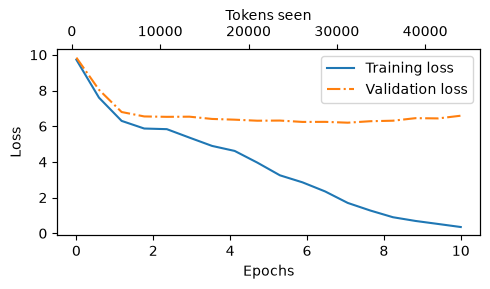

In [19]:
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator


def plot_losses(epochs_seen, tokens_seen, train_losses, val_losses):
    fig, ax1 = plt.subplots(figsize=(5, 3))

    # Plot training and validation loss against epochs
    ax1.plot(epochs_seen, train_losses, label="Training loss")
    ax1.plot(epochs_seen, val_losses, linestyle="-.", label="Validation loss")
    ax1.set_xlabel("Epochs")
    ax1.set_ylabel("Loss")
    ax1.legend(loc="upper right")
    ax1.xaxis.set_major_locator(MaxNLocator(integer=True))  # only show integer labels on x-axis

    # Create a second x-axis for tokens seen
    ax2 = ax1.twiny()  # Create a second x-axis that shares the same y-axis
    ax2.plot(tokens_seen, train_losses, alpha=0)  # Invisible plot for aligning ticks
    ax2.set_xlabel("Tokens seen")

    fig.tight_layout()  # Adjust layout to make room
    plt.show()

epochs_tensor = torch.linspace(0, num_epochs, len(train_losses))
plot_losses(epochs_tensor, tokens_seen, train_losses, val_losses)

In [20]:
model.eval()
model.reset_kv_cache()
context_size = model.pos_emb.weight.shape[0]
with torch.no_grad():
    token_ids = generate_text_simple_cached(
        model=model,
        idx=text_to_token_ids("Every effort moves you", tokenizer).to(device),
        max_new_tokens=25,
        context_size=context_size
    )

decoded_text = token_ids_to_text(token_ids, tokenizer)
print(decoded_text.replace("\n", " "))  # Compact print format



Every effort moves you?"  "Yes--quite insensible to the irony. She wanted him vindicated--and by me!"  


In [21]:
def softmax_with_temperature(logits, temperature):
    scaled_logits = logits / temperature
    return torch.softmax(scaled_logits, dim=0)


next_token_logits = torch.tensor(
    [4.51, 0.89, -1.90, 6.75, 1.63, -1.62, -1.89, 6.28, 1.79]
)
top_k = 3


top_logits, top_pos = torch.topk(next_token_logits, top_k)

print("Top logits:", top_logits)
print("Top positions:", top_pos)


new_logits = torch.where(
    condition=next_token_logits < top_logits[-1],
    input=torch.tensor(float("-inf")),
    other=next_token_logits
)

print(new_logits)


topk_probas = torch.softmax(new_logits, dim=0)
print(topk_probas)

Top logits: tensor([6.7500, 6.2800, 4.5100])
Top positions: tensor([3, 7, 0])
tensor([4.5100,   -inf,   -inf, 6.7500,   -inf,   -inf,   -inf, 6.2800,   -inf])
tensor([0.0615, 0.0000, 0.0000, 0.5775, 0.0000, 0.0000, 0.0000, 0.3610, 0.0000])


In [34]:
batch_input = torch.cat([
    text_to_token_ids("Every effort moves you", tokenizer).to(device),
    text_to_token_ids("Every effort moves you", tokenizer).to(device),
], dim = 0)

batch_input.shape

torch.Size([2, 4])

In [50]:
def generate(model, idx, max_new_tokens, context_size, temperature = 0.0, top_k=None, eos_id=None):
    model.eval()
    ctx_len = model.pos_emb.num_embeddings or context_size
    kv_window_size = model.kv_window_size

    with torch.no_grad():
        input_tokens = idx[:, -ctx_len:]
        input_tokens_lengths = input_tokens.size(1)

        for i in range(0, input_tokens_lengths, kv_window_size):
            chunk = input_tokens[:, i:i + kv_window_size]
            logits = model(chunk, use_cache=True)
            
        max_generable = ctx_len - input_tokens_lengths
        max_new_tokens = min(max_generable, max_new_tokens)

        for _ in range(max_new_tokens):
            logits = logits[:, -1, :]

            if top_k is not None:
                top_logits, _ = torch.topk(logits, top_k)
                min_val = top_logits[:, -1].unsqueeze(1)
                logits = torch.where(logits < min_val, torch.tensor(float("-inf")).to(logits.device), logits)

            if temperature > 0.0:
                logits = logits / temperature
                logits = logits - logits.max(dim=-1, keepdim=True).values

                probs = torch.softmax(logits, dim=-1)
                next_idx = torch.multinomial(probs, num_samples=1)

            else:
                next_idx = torch.argmax(logits, dim=-1, keepdim=True)

            if next_idx == eos_id: 
                break
            
            idx = torch.cat([idx, next_idx], dim=1)
            logits = model(next_idx, use_cache=True)

    return idx

            

In [53]:
torch.manual_seed(123)

model.reset_kv_cache()

token_ids = generate(
    model=model,
    idx=batch_input,
    max_new_tokens=15,
    context_size=GPT_CONFIG_124M["context_length"],
    top_k=25,
    temperature=1.4
)

print("Output text:\n", token_ids_to_text(token_ids[0], tokenizer))
print("Output text:\n", token_ids_to_text(token_ids[0], tokenizer))

Output text:
 Every effort moves you say to work on my dear, as it were, so with a feather
Output text:
 Every effort moves you say to work on my dear, as it were, so with a feather
